# Customer Personality Analysis
## Quem são os clientes que concentram o gasto?

**Projeto acadêmico de Ciência de Dados** — análise exploratória, estatística descritiva e testes de hipótese sobre 2.240 clientes de uma empresa de varejo.

**Pergunta central:** qual é o perfil dos 25% de clientes de maior gasto, como eles se comparam aos demais e qual é sua participação no gasto total?

**Como ler este notebook:** cada seção começa com a pergunta analítica, apresenta a tabela/gráfico correspondente e termina com a interpretação. Todos os números são calculados na execução — nada é digitado à mão. O código reutilizável está em `src/`, as tabelas em `outputs/tables/` e as figuras em `outputs/figures/`.

**Reprodutibilidade:** `python src/run_all.py` gera todos os artefatos; este notebook executa o mesmo pipeline módulo a módulo.


## 1. Contexto, objetivos e perguntas de pesquisa

A base descreve clientes de uma empresa de varejo com atributos demográficos (ano de nascimento, escolaridade, estado civil, filhos), financeiros (renda anual) e comportamentais (gasto em seis categorias de produtos, compras por canal, compras com desconto, visitas ao site, adesão a campanhas).

**Objetivo geral:** identificar e caracterizar os clientes de maior gasto e investigar quais atributos estão associados à concentração de gastos.

**Perguntas que o trabalho responde:**

| # | Pergunta | Onde é respondida |
|---|----------|-------------------|
| P1 | Qual é o perfil do cliente que mais gasta? | Seções 6 e 7 |
| P2 | Qual é o canal de compra preferido desse grupo? | Seção 8 |
| P3 | Eles utilizam descontos? | Seção 9 |
| P4 | Qual categoria de produto concentra seus gastos? | Seção 10 |
| P5 | Qual público-alvo concentra a maior parte do gasto total? | Seção 11 |
| P6 | Quais são suas características de renda, escolaridade, idade e filhos? | Seções 7 e 11 |
| P7 | Qual é a participação dos clientes de alto gasto no gasto total? | Seção 6 |
| P8 | Existe relação entre renda e gastos? | Seções 12 e 13 |
| P9 | O tempo de relacionamento influencia a leitura do volume de gastos? | Seção 13 |

**Definição operacional adotada:** cliente de alto gasto é aquele cujo `GastoTotal` (soma de `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds`) é maior ou igual ao percentil 75 da distribuição. O `GastoTotal` é tratado como **aproximação do faturamento gerado pelo cliente**, porque a base não possui margem, lucro nem valor monetário por canal.


In [1]:
# Configuração: caminhos absolutos para o projeto funcionar de qualquer diretório
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import analysis as an
import feature_engineering as fe
import preprocessing as pp
import visualization as viz

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))
print("Bibliotecas carregadas. Raiz do projeto:", RAIZ)


Bibliotecas carregadas. Raiz do projeto: /home/jonas/Área de trabalho/cd


## 2. Inspeção e compreensão dos dados

Antes de qualquer análise, inspecionamos o arquivo real: separador, dimensões, tipos e cardinalidade. O arquivo `data/raw/marketing_campaign.csv` é **separado por tabulação** e tem 2.240 linhas — a inspeção confirmou a estrutura esperada (29 atributos), sem necessidade de ajustes de leitura.


In [2]:
bruto = pp.carregar_bruto()
print(f"Linhas: {bruto.shape[0]} | Colunas: {bruto.shape[1]}")
bruto.head(3)


Linhas: 2240 | Colunas: 29


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,"58.138,00",0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,"46.344,00",1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,"71.613,00",0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0


In [3]:
perfil = pp.perfil_colunas(bruto)
perfil.groupby("Tipo_analitico").size().to_frame("Quantidade de variaveis")


,Quantidade de variaveis
Tipo_analitico,
Binária,7
Categórica,2
Constante,2
Identificadora,1
Numérica discreta,16
Temporal,1


In [4]:
perfil[["Variavel", "Tipo_analitico", "N_unicos", "Ausentes", "Exemplo"]]


,Variavel,Tipo_analitico,N_unicos,Ausentes,Exemplo
0,ID,Identificadora,2240,0,5524
1,Year_Birth,Numérica discreta,59,0,1957
2,Education,Categórica,5,0,Graduation
3,Marital_Status,Categórica,8,0,Single
4,Income,Numérica discreta,1974,24,"58.138,00"
5,Kidhome,Numérica discreta,3,0,0
6,Teenhome,Numérica discreta,3,0,0
7,Dt_Customer,Temporal,663,0,04-09-2012
8,Recency,Numérica discreta,100,0,58
9,MntWines,Numérica discreta,776,0,635


In [5]:
# Estatísticas descritivas iniciais das variáveis numéricas originais
pp.descritivas(bruto).head(14)


,Variavel,N,Media,Mediana,Desvio_padrao,Minimo,Q1,Q3,Maximo,Assimetria,Curtose,CV
0,ID,2240,"5.592,16","5.458,50","3.246,66","0,00","2.828,25","8.427,75","11.191,00","0,04","-1,19","0,58"
1,Year_Birth,2240,"1.968,81","1.970,00","11,98","1.893,00","1.959,00","1.977,00","1.996,00","-0,35","0,72","0,01"
2,Income,2216,"52.247,25","51.381,50","25.173,08","1.730,00","35.303,00","68.522,00","666.666,00","6,76","159,64","0,48"
3,Kidhome,2240,"0,44","0,00","0,54","0,00","0,00","1,00","2,00","0,64","-0,78","1,21"
4,Teenhome,2240,"0,51","0,00","0,55","0,00","0,00","1,00","2,00","0,41","-0,99","1,08"
5,Recency,2240,"49,11","49,00","28,96","0,00","24,00","74,00","99,00","-0,00","-1,20","0,59"
6,MntWines,2240,"303,94","173,50","336,60","0,00","23,75","504,25","1.493,00","1,18","0,60","1,11"
7,MntFruits,2240,"26,30","8,00","39,77","0,00","1,00","33,00","199,00","2,10","4,05","1,51"
8,MntMeatProducts,2240,"166,95","67,00","225,72","0,00","16,00","232,00","1.725,00","2,08","5,52","1,35"
9,MntFishProducts,2240,"37,52","12,00","54,63","0,00","3,00","50,00","259,00","1,92","3,10","1,46"


**Leitura da inspeção.** A base tem 2.240 clientes e não possui duplicatas nem identificadores repetidos. Três variáveis exigem atenção imediata:

- `Income` tem **24 ausentes (1,07%)** e um valor de 666.666 (12,7× a mediana), incompatível com o gasto observado desse cliente — comportamento típico de erro de digitação.
- `Year_Birth` tem três registros que implicam idade superior a 100 anos.
- `Marital_Status` traz rótulos não padronizados (`Alone`, `Absurd`, `YOLO`).

`Z_CostContact` e `Z_Revenue` são **constantes** (3 e 11) e não têm poder discriminante. As seis colunas de gasto são contagens em unidades monetárias (u.m.), com forte assimetria à direita (assimetria entre 1,2 e 2,1), o que já indica que medianas e testes não paramétricos serão mais adequados que médias e testes t de Student.


## 3. Qualidade dos dados e tratamento

Cada problema investigado, sua frequência e a decisão adotada estão na tabela abaixo. Nenhuma linha foi eliminada: a base preserva todos os clientes, e as ausências são tratadas apenas nas análises que dependem da variável afetada.


In [6]:
qualidade = pp.tabela_qualidade(bruto)
qualidade


,Problema,Variavel,Ocorrencias,Decisao,Percentual
0,Registros duplicados (linhas completas),todas,0,Nenhum; base mantida integralmente.,"0,00"
1,Identificadores (ID) repetidos,ID,0,Nenhum; ID é chave única (usado apenas como id...,"0,00"
2,Renda ausente,Income,24,Mantidos como ausentes; excluídos apenas das a...,"1,07"
3,Renda implausível (>= 600.000),Income,1,Convertida em ausente (erro de digitação prová...,"0,04"
4,Idade implausível (> 100 anos),Year_Birth,3,Idade tratada como ausente nesses casos; demai...,"0,13"
5,Estado civil fora do padrão (Alone/Absurd/YOLO),Marital_Status,7,Alone -> Solteiro(a); Absurd/YOLO -> Outros (4...,"0,31"
6,Escolaridade fora do padrão,Education,0,"5 rótulos válidos (Basic, Graduation, 2n Cycle...","0,00"
7,Datas inválidas (Dt_Customer),Dt_Customer,0,Nenhuma; conversão com formato explícito %d-%m...,"0,00"
8,Valores negativos em atributos não negativos,numéricas,0,Nenhum; nenhum ajuste necessário.,"0,00"
9,Colunas constantes,"Z_CostContact, Z_Revenue",2,"Removidas: valor único (3 e 11), sem poder dis...","0,09"


**Justificativas dos tratamentos**

1. **Renda ausente (24 casos):** não foram imputadas. Imputar renda por mediana criaria um valor artificial justamente no atributo mais associado ao gasto, contaminando as comparações. Esses clientes permanecem na base e são excluídos somente das análises que usam renda (n = 2.215 nessas análises).
2. **Renda 666.666 (1 caso):** convertida em ausente. O padrão de dígitos repetidos, o valor 12,7× a mediana e o gasto total de apenas 27 u.m. indicam erro de entrada, não um cliente de alta renda.
3. **Idades > 100 anos (3 casos):** idade tratada como ausente; as demais variáveis do cliente continuam válidas. Idades entre 70 e 90 anos foram **mantidas** — são plausíveis e o gasto desses clientes é informação legítima.
4. **Estados civis não padronizados:** `Alone` (3) foi agregado a "Solteiro(a)", interpretação direta do rótulo; `Absurd` (2) e `YOLO` (2) foram mantidos como "Outros", sem inventar uma categoria de estado civil.
5. **Escolaridade:** os cinco rótulos originais foram apenas traduzidos (`Basic`→Básico, `Graduation`→Graduação, `2n Cycle`→Ciclo 2, `Master`→Mestrado, `PhD`→Doutorado). Nenhum registro teve escolaridade inválida.
6. **Outliers:** a regra 1,5 IQR sinaliza 3 clientes com gasto extremo, 8 com renda extrema e 3 com idade extrema (exatamente os três casos de idade impossível já tratados). **Nenhum cliente foi removido da base**: os gastos extremos são consumidores de alto padrão, o próprio objeto de interesse do trabalho — eliminá-los subestimaria a concentração de gasto, que é justamente o resultado central.


In [7]:
# Aplicação dos tratamentos e conferência
limpo = pp.limpar(bruto)
print("Colunas removidas:", sorted(set(bruto.columns) - set(limpo.columns)))
print("Ausentes após limpeza:")
print(limpo.isna().sum()[limpo.isna().sum() > 0].to_string())
print("Estados civis:", limpo["EstadoCivil"].value_counts().to_dict())
print("Escolaridade:", limpo["Escolaridade"].value_counts().sort_index().to_dict())


Colunas removidas: ['Education', 'Marital_Status', 'Z_CostContact', 'Z_Revenue']
Ausentes após limpeza:
Year_Birth     3
Income        25
Estados civis: {'Casado(a)': 864, 'União estável': 580, 'Solteiro(a)': 483, 'Divorciado(a)': 232, 'Viúvo(a)': 77, 'Outros': 4}
Escolaridade: {'Básico': 54, 'Graduação': 1127, 'Ciclo 2': 203, 'Mestrado': 370, 'Doutorado': 486}


## 4. Engenharia de atributos

Foram criados: `GastoTotal`, `Idade`, `TotalFilhos`, `TempoRelacionamento`, `GastoMensal`, `SegmentoGasto`, a participação de cada categoria no gasto individual, o total de compras e as faixas usadas na análise de público-alvo.

**Data de referência (decisão metodológica central).** A base não documenta a data em que foi extraída. Como o gasto é acumulado desde o cadastro, a extração ocorreu necessariamente **depois** do último cadastro presente. Adotamos a proxy mais conservadora disponível: **29-06-2014**, a maior data em `Dt_Customer`. Consequências:

- `TempoRelacionamento` = (data de referência − `Dt_Customer`) em meses (dividindo os dias por 30,4375).
- Se a extração real ocorreu depois, o tempo de relacionamento é **subestimado em uma constante** para todos os clientes, o que não altera comparações entre grupos nem a ordenação do gasto mensal, mas reduz o nível do gasto mensal calculado.
- Dois clientes cadastrados na própria data de referência têm tempo zero. Para eles `GastoMensal` fica ausente (nunca infinito), e eles são excluídos apenas das análises de gasto mensal.

**Segmentação e empates no percentil.** O limite é o percentil 75 de `GastoTotal`, e o grupo de alto gasto inclui **todos** os clientes com `GastoTotal` maior ou igual ao limite. Isso mantém a regra transparente quando há empates no valor de corte. Nesta base o percentil 75 vale 1.045,5 e **nenhum cliente tem exatamente esse gasto**, portanto o grupo fica com exatamente 25% da base.


In [8]:
referencia = fe.data_referencia(limpo)
df = an.adicionar_canal_predominante(fe.adicionar_faixas(fe.construir_atributos(limpo, referencia)))

limite = df["GastoTotal"].quantile(0.75)
print(f"Data de referência (proxy): {referencia:%d-%m-%Y}")
print(f"Percentil 75 do GastoTotal: {limite:,.2f}")
print(f"Clientes com gasto exatamente igual ao limite (empates): {(df['GastoTotal'] == limite).sum()}")
print(f"Clientes com tempo de relacionamento zero: {(df['TempoRelacionamento'] == 0).sum()}")
print(df["SegmentoGasto"].value_counts().to_string())
print(df["SegmentoGasto"].value_counts(normalize=True).mul(100).round(2).to_string())


Data de referência (proxy): 29-06-2014
Percentil 75 do GastoTotal: 1,045.50
Clientes com gasto exatamente igual ao limite (empates): 0
Clientes com tempo de relacionamento zero: 2
SegmentoGasto
Demais clientes    1680
Alto gasto          560
SegmentoGasto
Demais clientes   75,00
Alto gasto        25,00


In [9]:
# Estatísticas das variáveis derivadas (inclui o gasto mensal normalizado)
pp.descritivas(df, ["GastoTotal", "Idade", "TotalFilhos", "TempoRelacionamento", "GastoMensal", "TotalCompras"])


,Variavel,N,Media,Mediana,Desvio_padrao,Minimo,Q1,Q3,Maximo,Assimetria,Curtose,CV
0,GastoTotal,2240,"605,80","396,00","602,25","5,00","68,75","1.045,50","2.525,00","0,86","-0,34","0,99"
1,Idade,2237,"45,10","44,00","11,70","18,00","37,00","55,00","74,00","0,09","-0,80","0,26"
2,TotalFilhos,2240,"0,95","1,00","0,75","0,00","0,00","1,00","3,00","0,42","-0,25","0,79"
3,TempoRelacionamento,2240,"11,62","11,68","6,64","0,00","5,94","17,38","22,96","-0,01","-1,20","0,57"
4,GastoMensal,2238,"175,85","37,50","1.237,65","0,34","9,50","91,76","29.950,50","17,71","355,90","7,04"
5,TotalCompras,2240,"12,54","12,00","7,21","0,00","6,00","18,00","32,00","0,30","-1,12","0,57"


As variáveis derivadas confirmam o esperado: `GastoTotal` varia de 5 a 2.525 u.m., com mediana de 396 e média de 606 — média acima da mediana é a assinatura da assimetria à direita. `GastoMensal` tem assimetria ainda maior porque clientes muito recentes podem ter acumulado pouco gasto em poucos dias; por isso, **todas as comparações de gasto mensal usam a mediana**, com a média reportada apenas como complemento.


## 5. Análise exploratória geral

As três primeiras figuras respondem a uma pergunta simples e necessária: como se distribuem renda, idade e gasto? A forma dessas distribuições define quais estatísticas resumem bem os dados (mediana em vez de média) e quais testes são apropriados.


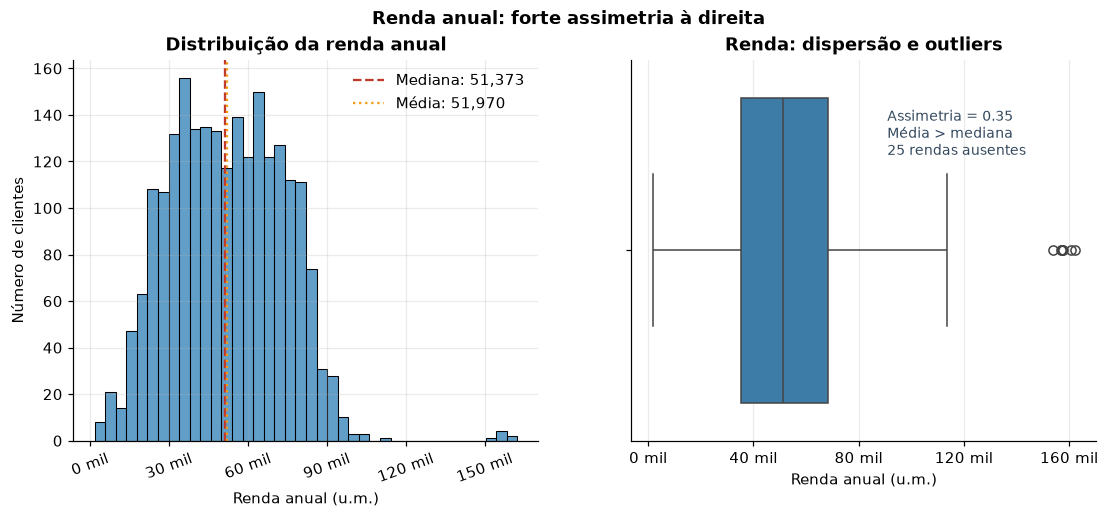

In [10]:
viz.fig_distribuicao_renda(df)
plt.show()


**Renda.** A distribuição é assimétrica à direita (assimetria 0,35), com mediana de 51.373 u.m. e média de 51.970 u.m. A cauda contém clientes de alta renda que puxam a média para cima: por isso o trabalho usa mediana e quartis nas comparações. A concentração maior está entre 30 e 70 mil u.m.


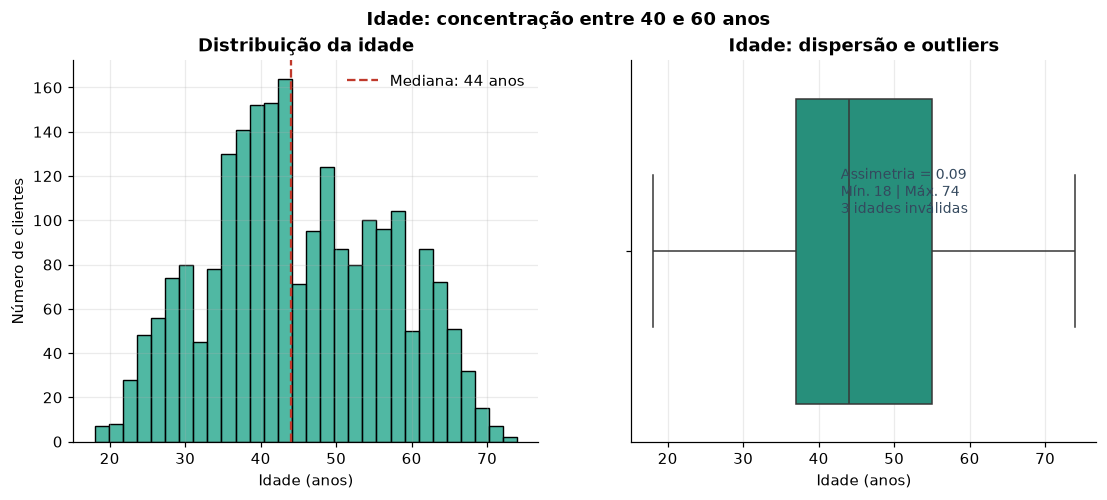

In [11]:
viz.fig_distribuicao_idade(df)
plt.show()


**Idade.** A distribuição é aproximadamente simétrica (assimetria 0,09), centrada em 44 anos, com a maior parte entre 37 e 55 anos. Há poucos clientes acima de 70 anos, mas eles foram mantidos por serem plausíveis.


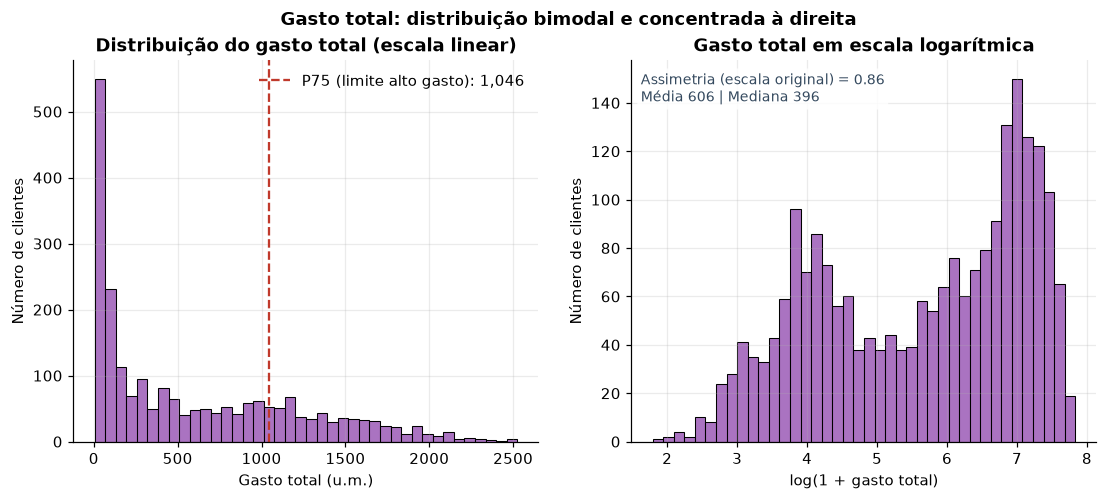

In [12]:
viz.fig_distribuicao_gasto(df)
plt.show()


**Gasto total.** A distribuição é **bimodal** (assimetria 0,86): um grupo numeroso com gasto próximo de zero e um grupo com gasto elevado, separados por uma região de baixa densidade. Isso não é acidente estatístico — reflete dois comportamentos de consumo distintos na base, e é o que torna a segmentação por percentil informativa. A mediana é 396 u.m. e a média 606 u.m.


In [13]:
# Síntese das variáveis categóricas e de frequência
pd.DataFrame({
    "Escolaridade (%)": df["Escolaridade"].value_counts(normalize=True).mul(100).round(1),
    "Estado civil (%)": df["EstadoCivil"].value_counts(normalize=True).mul(100).round(1),
    "Filhos (%)": df["FaixaFilhos"].value_counts(normalize=True).mul(100).round(1),
    "Faixa etária (%)": df["FaixaEtaria"].value_counts(normalize=True).mul(100).round(1),
})


,Escolaridade (%),Estado civil (%),Filhos (%),Faixa etária (%)
1 filho,NaN,NaN,"50,40",NaN
18-29,NaN,NaN,NaN,"9,90"
2 filhos,NaN,NaN,"18,80",NaN
3+ filhos,NaN,NaN,"2,40",NaN
30-39,NaN,NaN,NaN,"24,90"
40-49,NaN,NaN,NaN,"30,20"
50-59,NaN,NaN,NaN,"20,90"
60+,NaN,NaN,NaN,"14,10"
Básico,"2,40",NaN,NaN,NaN
Casado(a),NaN,"38,60",NaN,NaN


In [14]:
df[["Recency", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumDealsPurchases", "NumWebVisitsMonth"]].describe().T


,count,mean,std,min,25%,50%,75%,max
Recency,"2.240,00","49,11","28,96","0,00","24,00","49,00","74,00","99,00"
NumWebPurchases,"2.240,00","4,08","2,78","0,00","2,00","4,00","6,00","27,00"
NumCatalogPurchases,"2.240,00","2,66","2,92","0,00","0,00","2,00","4,00","28,00"
NumStorePurchases,"2.240,00","5,79","3,25","0,00","3,00","5,00","8,00","13,00"
NumDealsPurchases,"2.240,00","2,33","1,93","0,00","1,00","2,00","3,00","15,00"
NumWebVisitsMonth,"2.240,00","5,32","2,43","0,00","3,00","6,00","7,00","20,00"


**Perfil médio da base.** Predomínio de graduados, casados ou em união estável, com um filho em casa. A loja física é o canal com mais compras (mediana 5), seguida de web (mediana 4) e catálogo (mediana 2). Quase todos os clientes usaram alguma oferta (mediana 2 compras com desconto), e a recência mediana é de 49 dias desde a última compra.


## 6. Identificação dos clientes de alto gasto

Aqui se aplica a definição central: clientes com `GastoTotal` no quartil superior. A tabela responde diretamente à pergunta P7 (participação no gasto total) e serve de base para todas as comparações seguintes.


In [15]:
resumo = an.resumo_segmentos(df)
resumo


,Grupo,N_clientes,Percentual_clientes,Limite_P75_GastoTotal,Gasto_acumulado,Participacao_gasto_total,Media_gasto,Mediana_gasto,Desvio_gasto,Media_gasto_mensal,Mediana_gasto_mensal
0,Alto gasto,560,"25,00","1.045,50",834666,"61,51","1.490,48","1.440,00","329,31","355,12","108,18"
1,Demais clientes,1680,"75,00","1.045,50",522322,"38,49","310,91","160,50","315,47","116,03","19,59"
2,Total,2240,"100,00","1.045,50",1356988,"100,00","605,80","396,00","602,25","175,85","37,50"


In [16]:
# Concentração: quanto do gasto está nos maiores gastadores
deceis = an.concentracao_por_decil(df)
deceis


,Decil_maiores_gastos,Perc_clientes,Perc_gasto_acumulado
0,1,"10,00","30,16"
1,2,"20,00","52,33"
2,3,"30,00","69,64"
3,4,"40,00","82,57"
4,5,"50,00","90,78"
5,6,"60,00","95,53"
6,7,"70,00","97,74"
7,8,"80,00","98,89"
8,9,"90,00","99,63"
9,10,"100,00","100,00"


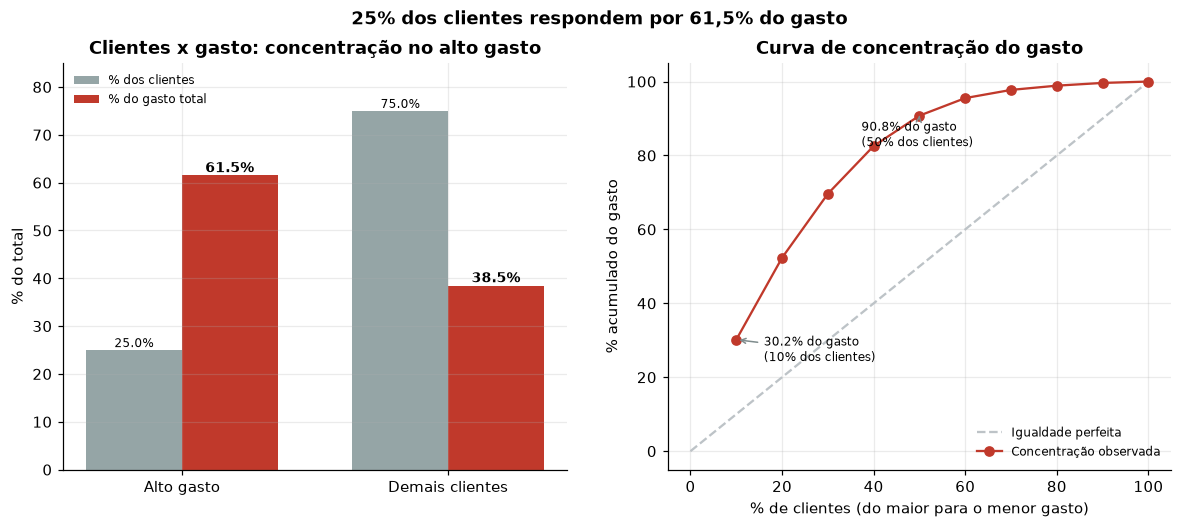

In [17]:
viz.fig_participacao(df, resumo, deceis)
plt.show()


**Resultado central.** O limite do quartil superior é **1.045,50 u.m.** Os 560 clientes de alto gasto (25,00% da base) somam **61,51% do gasto total** (834.666 de 1.356.988 u.m.). Os 1.680 demais clientes respondem por 38,49%.

A concentração é ainda mais forte dentro do grupo: os 10% maiores gastadores respondem por 30,2% do gasto e os 20% maiores por 52,3%. O gasto médio do grupo de alto gasto é 1.490 u.m. contra 311 u.m. (4,8×); a mediana é 1.440 contra 160 u.m. (9,0×). A diferença entre esses dois múltiplos mostra que o grupo de alto gasto é internamente mais homogêneo que o restante da base.


## 7. Comparação do perfil dos clientes

Seguimos a mesma segmentação para comparar perfil financeiro, demográfico e temporal. As figuras mostram distribuições; a tabela mostra os números que sustentam a leitura.


In [18]:
comparacao = an.comparacao_grupos(df)
comparacao


,Variavel,N_alto,Media_alto,Mediana_alto,N_demais,Media_demais,Mediana_demais,Diferenca_medias,Razao_medias,Razao_medianas
0,Renda anual,556,"75.238,19","75.295,50",1659,"44.171,68","42.691,00","31.066,52","1,70","1,76"
1,Idade (anos),559,"45,99","45,00",1678,"44,80","43,00","1,19","1,03","1,05"
2,Número de filhos,560,"0,38","0,00",1680,"1,14","1,00","-0,76","0,33","0,00"
3,Tempo de relacionamento (meses),560,"13,05","13,85",1680,"11,14","10,94","1,91","1,17","1,27"
4,Gasto total (u.m.),560,"1.490,47","1.440,00",1680,"310,91","160,50","1.179,57","4,79","8,97"
5,Gasto mensal (u.m./mês),560,"355,12","108,19",1678,"116,03","19,59","239,09","3,06","5,52"
6,Total de compras (n),560,"19,99","20,00",1680,"10,05","7,00","9,94","1,99","2,86"
7,Compras com desconto (n),560,"1,86","1,00",1680,"2,48","2,00","-0,62","0,75","0,50"
8,Visitas ao site por mês (n),560,"3,62","3,00",1680,"5,88","6,00","-2,27","0,61","0,50"


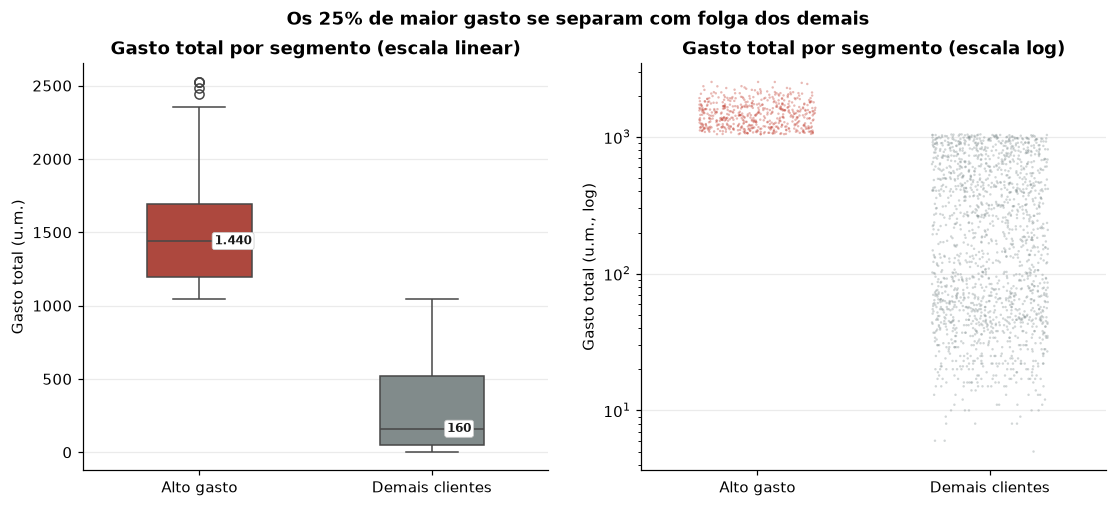

In [19]:
viz.fig_gasto_por_grupo(df)
plt.show()


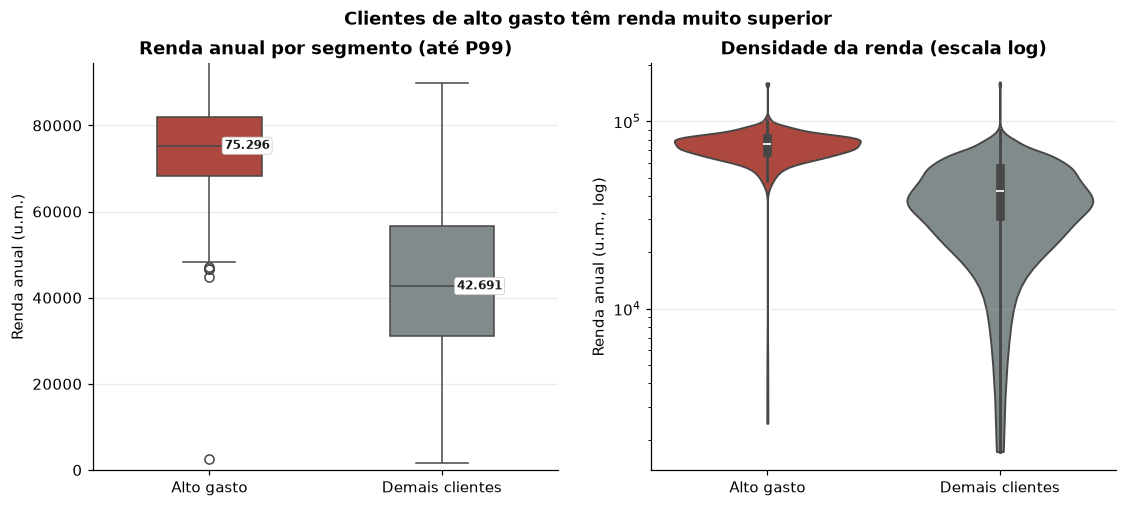

In [20]:
viz.fig_renda_por_grupo(df)
plt.show()


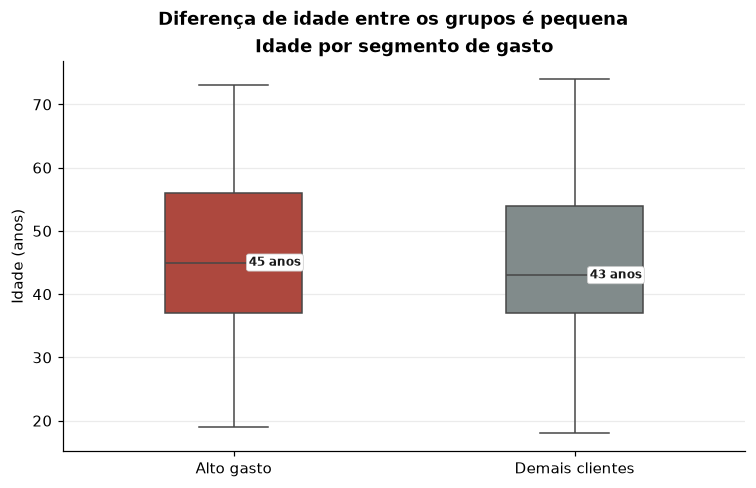

In [21]:
viz.fig_idade_por_grupo(df)
plt.show()


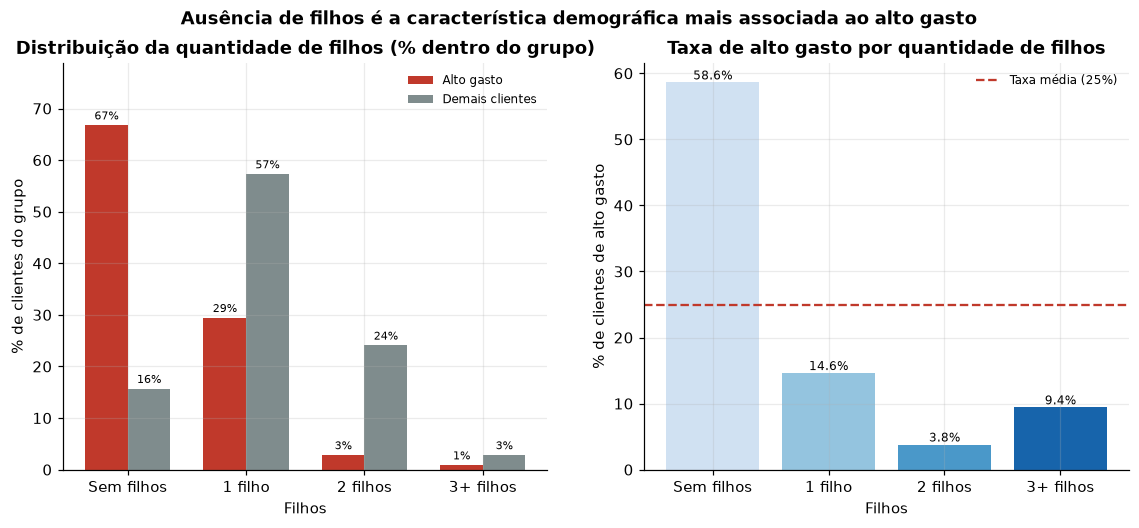

In [22]:
viz.fig_filhos_por_grupo(df)
plt.show()


In [23]:
perfil_cat = an.perfil_categorico(df)
perfil_cat


,Dimensao,Categoria,N,Percentual_dentro_alto,Percentual_dentro_demais,Taxa_alto_gasto
0,Escolaridade,Básico,54,"0,00","3,21","0,00"
1,Escolaridade,Graduação,1127,"52,32","49,64","26,00"
2,Escolaridade,Ciclo 2,203,"7,50","9,58","20,69"
3,Escolaridade,Mestrado,370,"14,82","17,08","22,43"
4,Escolaridade,Doutorado,486,"25,36","20,48","29,22"
5,Estado civil,Casado(a),864,"35,89","39,46","23,26"
6,Estado civil,Divorciado(a),232,"10,89","10,18","26,29"
7,Estado civil,Outros,4,"0,36","0,12","50,00"
8,Estado civil,Solteiro(a),483,"22,68","21,19","26,29"
9,Estado civil,União estável,580,"25,36","26,07","24,48"


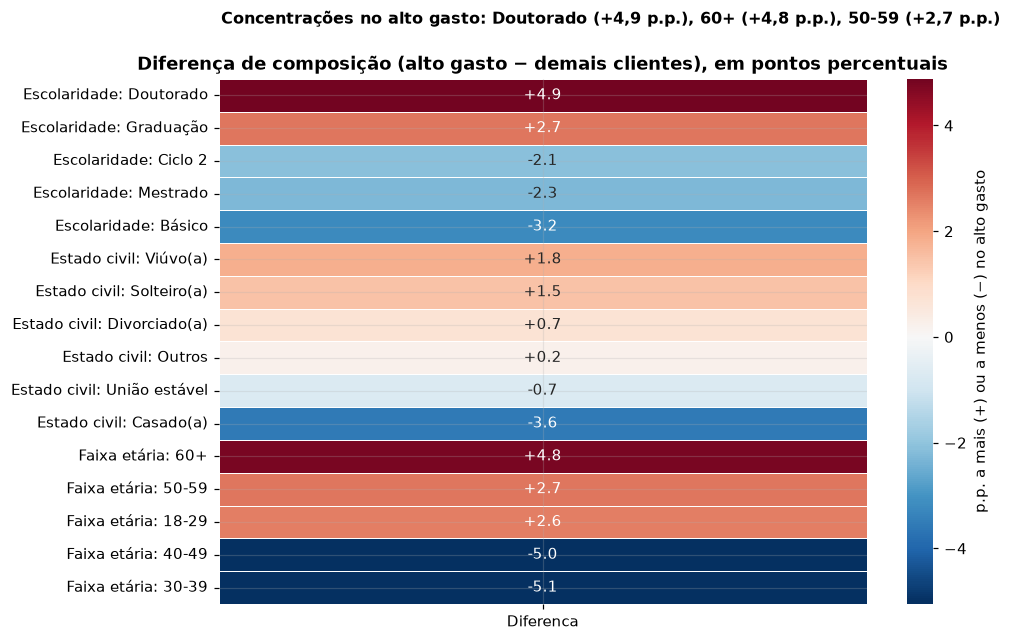

In [24]:
viz.fig_perfil_demografico(df)
plt.show()


**Perfil financeiro.** Renda é a diferença mais nítida: mediana de 75.296 u.m. no alto gasto contra 42.691 u.m. nos demais (1,76×). As distribuições se sobrepõem apenas nas faixas altas: o cliente típico de alto gasto está acima de 70 mil u.m. de renda anual, e a cauda inferior do grupo é pequena.

**Perfil demográfico.** A idade praticamente não separa os grupos (medianas de 45 e 43 anos; diferença de 1,2 ano na média). Já o número de filhos é um divisor forte: média de 0,38 contra 1,14. Entre os clientes de alto gasto, 66,8% não têm filhos, contra 15,7% entre os demais. Escolaridade mostra diferença pequena mas consistente: doutorado é a categoria com maior taxa de alto gasto (29,2%) e básico tem 0,0% — nenhum cliente com escolaridade básica está no quartil superior. O estado civil **não** separa os grupos de forma relevante (taxas de alto gasto entre 23,3% e 35,1%, excluindo a categoria residual "Outros").

**Perfil temporal.** O tempo de relacionamento mediano é de 13,8 meses no alto gasto contra 10,9 meses nos demais. A diferença é pequena em magnitude, mas relevante para a interpretação: o grupo de alto gasto é ligeiramente **mais antigo**, o que reforça, e não explica, seu gasto acumulado. Normalizando pelo tempo, a mediana do gasto mensal é de 108,18 u.m./mês no alto gasto contra 19,59 u.m./mês nos demais (5,5×), conforme detalhado na Seção 13.

**Relacionamento com a empresa.** A recência (dias desde a última compra) e o volume de compras completam o quadro: o alto gasto concentra mais compras (20 contra 7).


## 8. Canais de compra

**Pergunta:** qual canal os clientes de alto gasto usam mais? A base registra a **quantidade de compras** por canal (`NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases`), não o valor gasto em cada canal. Portanto, a análise mede frequência de compras — nunca faturamento por canal.


In [25]:
canais = an.analise_canais(df)
canais


,Canal,Grupo,N_clientes,Total_compras,Media_por_cliente,Mediana_por_cliente,Participacao_no_grupo,Perc_clientes_com_compra
0,Web,Alto gasto,560,3139,"5,61","5,00","28,04","99,11"
1,Web,Demais clientes,1680,6011,"3,58","3,00","35,60","97,38"
2,Catálogo,Alto gasto,560,3309,"5,91","6,00","29,56","99,82"
3,Catálogo,Demais clientes,1680,2654,"1,58","1,00","15,72","65,18"
4,Loja física,Alto gasto,560,4748,"8,48","9,00","42,41","99,46"
5,Loja física,Demais clientes,1680,8222,"4,89","4,00","48,69","99,29"


In [26]:
an.canal_predominante(df)


SegmentoGasto,Alto gasto,Demais clientes,Total,Perc_alto,Perc_demais
CanalPredominante,,,,,
Catálogo,110,50,160,"19,64","2,98"
Loja física,342,1136,1478,"61,07","67,62"
Sem compras,0,6,6,"0,00","0,36"
Web,108,488,596,"19,29","29,05"


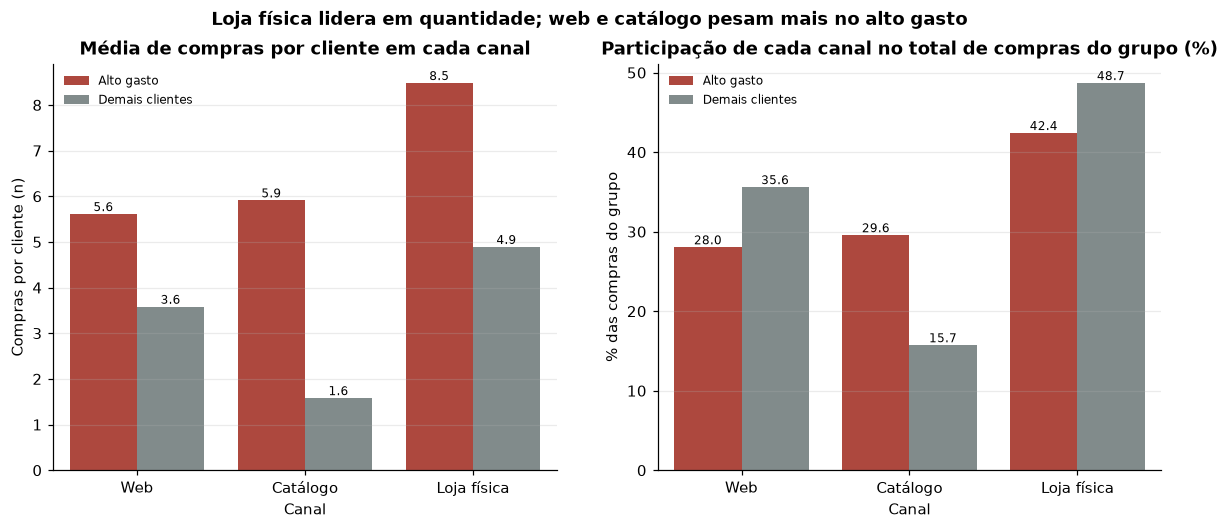

In [27]:
viz.fig_canais(df, canais)
plt.show()


**Quantidade.** A loja física continua sendo o canal mais usado pelos dois grupos, com média de 8,48 compras por cliente no alto gasto contra 4,89 nos demais. O que muda é a **intensidade relativa** dos outros canais: o catálogo salta de 1,58 para 5,91 compras por cliente (3,7×), e a web de 3,58 para 5,61.

**Composição.** No total de compras do grupo de alto gasto, a loja física responde por 42,4%, o catálogo por 29,6% e a web por 28,0%. Nos demais, a loja física pesa 48,7% e a web 35,6%. Ou seja: **o canal preferido em volume continua sendo a loja física**, mas o catálogo é o canal que mais distingue o segmento de alto gasto.

**Canal predominante** (maior número de compras do próprio cliente): 61,1% do grupo de alto gasto tem a loja física como canal dominante e 19,6% tem o catálogo, contra 3,0% nos demais clientes. O catálogo, portanto, funciona como marcador de perfil de alto valor.

**Limitação explícita:** como não existe valor monetário por canal, é incorreto afirmar que a loja física "gera mais faturamento". Ela gera mais **transações**; a distribuição do gasto entre canais é desconhecida.


## 9. Compras com desconto

**Pergunta:** os clientes de alto gasto usam descontos? `NumDealsPurchases` conta compras feitas com ofertas/descontos. O atributo **não comprova uso de cupom** — não há identificação de cupom na base, apenas a marcação de que a compra ocorreu com oferta.


In [28]:
descontos = an.analise_descontos(df)
dist_descontos = an.distribuicao_descontos(df).reset_index()
descontos


,Grupo,N_clientes,Media,Mediana,Desvio_padrao,Maximo,N_usuarios,Perc_usuarios,Media_entre_usuarios,Mediana_entre_usuarios,Total_de_compras_com_desconto
0,Alto gasto,560,"1,86","1,00","2,03",15,530,"94,64","1,96","1,00",1040
1,Demais clientes,1680,"2,48","2,00","1,87",15,1664,"99,05","2,50","2,00",4168


In [29]:
dist_descontos


SegmentoGasto,Compras_com_desconto,Alto gasto,Demais clientes
0,0,"5,36","0,95"
1,1,"62,68","36,85"
2,2,"12,14","25,54"
3,3,"7,68","15,12"
4,4,"4,11","9,88"
5,5+,"8,04","11,67"


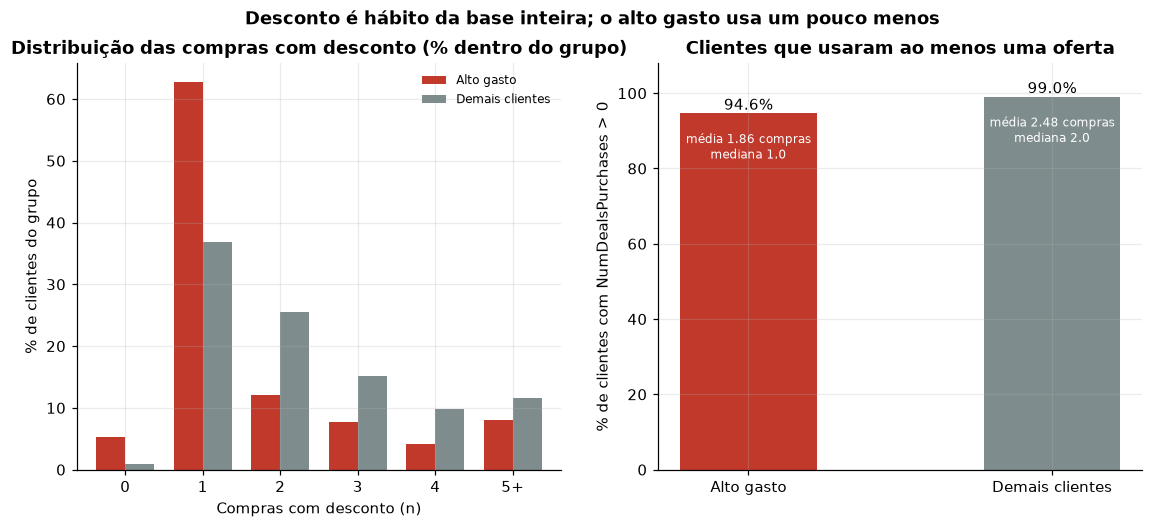

In [30]:
viz.fig_descontos(df, descontos, dist_descontos)
plt.show()


**Resultado.** O uso de ofertas é quase universal na base: 94,6% dos clientes de alto gasto e 99,0% dos demais usaram ao menos uma oferta. Contudo, a **intensidade** é menor no alto gasto: média de 1,86 compras com desconto contra 2,48 (1,0 vs 2,0 na mediana). Restringindo aos clientes que usaram ao menos uma oferta, a média cai para 1,96 no alto gasto e 2,50 nos demais.

**Interpretação.** Desconto não é o que move o segmento de alto valor: esses clientes compram com menos frequência em ofertas e concentram a compra em categorias de maior valor unitário. A distribuição mostra o padrão: 5,4% do alto gasto não usou nenhuma oferta, contra 0,9% dos demais, e a moda do alto gasto é 1 compra com desconto contra 2 nos demais. A leitura correta é **associação descritiva**, não causal: não se pode afirmar que dar desconto reduziria o gasto, nem que retirar descontos o aumentaria.


## 10. Categorias de produto

**Pergunta:** qual categoria concentra os gastos? A análise compara total, média, mediana e participação na cesta de cada grupo.


In [31]:
categorias = an.analise_categorias(df)
categorias


,Categoria,Gasto_total,Perc_gasto_global,Media_alto,Mediana_alto,Media_demais,Mediana_demais,Perc_dentro_cesta_alto,Perc_dentro_cesta_demais,Perc_do_gasto_da_categoria_no_alto,Razao_medias
0,Vinhos,680816,"50,17","739,27","736,50","158,82","68,00","49,60","51,08","60,81","4,65"
1,Frutas,58917,"4,34","62,11","50,00","14,37","4,00","4,17","4,62","59,04","4,32"
2,Carnes,373968,"27,56","456,79","420,00","70,34","30,00","30,65","22,62","68,40","6,49"
3,Peixes,84057,"6,19","89,47","76,00","20,21","7,00","6,00","6,50","59,61","4,43"
4,Doces,60621,"4,47","63,89","50,00","14,79","5,00","4,29","4,76","59,02","4,32"
5,Ouro,98609,"7,27","78,93","56,50","32,39","17,00","5,30","10,42","44,83","2,44"


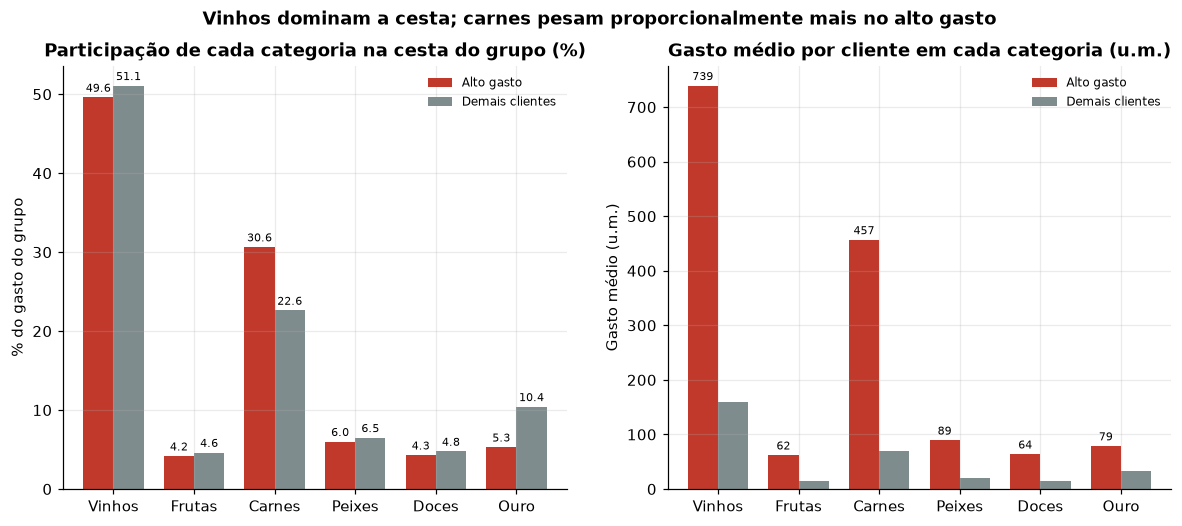

In [32]:
viz.fig_categorias(df, categorias)
plt.show()


**Total.** Vinhos concentram 50,2% de todo o gasto da base (680.816 u.m.), seguidos de carnes (27,6%), ouro (7,3%), peixes (6,2%), doces (4,5%) e frutas (4,3%).

**Cesta do alto gasto.** Vinhos respondem por 49,6% e carnes por 30,6% do gasto do grupo — juntas, 80,2%. Nos demais clientes, vinhos pesam 51,1% e carnes 22,6%. A diferença relevante está em **carnes** (proporcionalmente mais importante no alto gasto) e em **ouro** (proporcionalmente mais importante entre os demais: 10,4% contra 5,3%) — ouro funciona mais como compra ocasional de ticket baixo do que como pilar do alto gasto.

**Gasto médio por cliente.** Todas as categorias crescem no grupo de alto gasto, em diferentes graus: carnes 6,5×, vinhos 4,7×, frutas 4,3×, peixes 4,4×, doces 4,3× e ouro apenas 2,4×. O grupo de alto gasto é responsável por 68,4% de toda a venda de carnes e 60,8% de toda a venda de vinhos da base.


## 11. Identificação do público-alvo

**Pergunta:** quais perfis concentram os clientes de alto gasto? Aqui distinguimos duas medidas que costumam ser confundidas:

- **taxa de alto gasto** = probabilidade de um cliente daquele perfil pertencer ao grupo de alto gasto (P(alto | perfil));
- **participação nos altos** = quanto daquele perfil está dentro do grupo de alto gasto.

Um perfil pode ter taxa altíssima e participação pequena (grupo raro) — ou o contrário. Reportamos as duas, com intervalo de confiança de Wilson e `lift` (taxa do perfil ÷ taxa base de 25%).


In [33]:
publico = an.publico_alvo(df)
publico.style.format({"Taxa_alto_gasto": "{:.1f}", "Perc_dos_altos": "{:.1f}", "Lift": "{:.2f}"})


,Dimensao,Categoria,N,N_alto_gasto,Taxa_alto_gasto,IC95_inf,IC95_sup,Perc_dos_altos,Lift
0,Faixa de renda,Q1 (menor),443,1,0.2,0.040000,1.270000,0.2,0.01
1,Faixa de renda,Q2,443,0,0.0,0.000000,0.860000,0.0,0.00
2,Faixa de renda,Q3,443,30,6.8,4.780000,9.500000,5.4,0.27
3,Faixa de renda,Q4,443,173,39.0,34.620000,43.670000,30.9,1.56
4,Faixa de renda,Q5 (maior),443,352,79.5,75.450000,82.960000,62.9,3.18
5,Faixa etária,18-29,221,66,29.9,24.220000,36.200000,11.8,1.19
6,Faixa etária,30-39,557,118,21.2,17.990000,24.770000,21.1,0.85
7,Faixa etária,40-49,676,148,21.9,18.940000,25.160000,26.4,0.88
8,Faixa etária,50-59,467,128,27.4,23.560000,31.630000,22.9,1.10
9,Faixa etária,60+,316,99,31.3,26.470000,36.640000,17.7,1.25


In [34]:
# Recorte: faixas com maior taxa de alto gasto e n >= 50
publico[publico["N"] >= 50].sort_values("Taxa_alto_gasto", ascending=False).head(10)


,Dimensao,Categoria,N,N_alto_gasto,Taxa_alto_gasto,IC95_inf,IC95_sup,Perc_dos_altos,Lift
4,Faixa de renda,Q5 (maior),443,352,"79,46","75,45","82,96","62,86","3,18"
21,Quantidade de filhos,Sem filhos,638,374,"58,62","54,76","62,38","66,79","2,34"
3,Faixa de renda,Q4,443,173,"39,05","34,62","43,67","30,89","1,56"
20,Estado civil,Viúvo(a),77,27,"35,06","25,35","46,20","4,82","1,40"
28,Tempo de relacionamento,Q4 (mais antigo),554,184,"33,21","29,42","37,24","32,86","1,33"
9,Faixa etária,60+,316,99,"31,33","26,47","36,64","17,68","1,25"
5,Faixa etária,18-29,221,66,"29,86","24,22","36,20","11,79","1,19"
14,Escolaridade,Doutorado,486,142,"29,22","25,35","33,41","25,36","1,17"
8,Faixa etária,50-59,467,128,"27,41","23,56","31,63","22,86","1,10"
27,Tempo de relacionamento,Q3,566,149,"26,33","22,87","30,10","26,61","1,05"


In [35]:
combinacoes = an.combinacoes_perfis(df)
combinacoes


,Perfil,N,N_alto,Taxa_alto_gasto,Perc_dos_altos,Lift
0,Q5 (maior) | Sem filhos | Ensino superior,326,272,"83,44","48,92","3,32"
1,Q5 (maior) | 1 filho | Ensino superior,96,68,"70,83","12,23","2,82"
2,Q4 | Sem filhos | Ensino superior,135,88,"65,19","15,83","2,60"
3,Q4 | 1 filho | Ensino superior,254,77,"30,31","13,85","1,21"
4,Q3 | Sem filhos | Ensino superior,45,11,"24,44","1,98","0,97"
5,Q4 | 2 filhos | Ensino superior,48,7,"14,58","1,26","0,58"
6,Q3 | 1 filho | Ensino superior,253,19,"7,51","3,42","0,30"
7,Q1 (menor) | 1 filho | Ensino superior,243,1,"0,41","0,18","0,02"
8,Q2 | 1 filho | Ensino superior,235,0,"0,00","0,00","0,00"
9,Q2 | 2 filhos | Ensino superior,150,0,"0,00","0,00","0,00"


In [36]:
combinacoes_renda = an.combinacoes_renda_filhos(df)
combinacoes_renda


,FaixaRenda,FaixaFilhos,N,N_alto,Taxa_alto_gasto,Lift
0,Q1 (menor),Sem filhos,88,0,"0,00","0,00"
1,Q1 (menor),1 filho,278,1,"0,36","0,01"
2,Q1 (menor),2 filhos,71,0,"0,00","0,00"
3,Q1 (menor),3+ filhos,6,0,"0,00","0,00"
4,Q2,Sem filhos,39,0,"0,00","0,00"
5,Q2,1 filho,235,0,"0,00","0,00"
6,Q2,2 filhos,150,0,"0,00","0,00"
7,Q2,3+ filhos,19,0,"0,00","0,00"
8,Q3,Sem filhos,45,11,"24,44","0,97"
9,Q3,1 filho,253,19,"7,51","0,30"


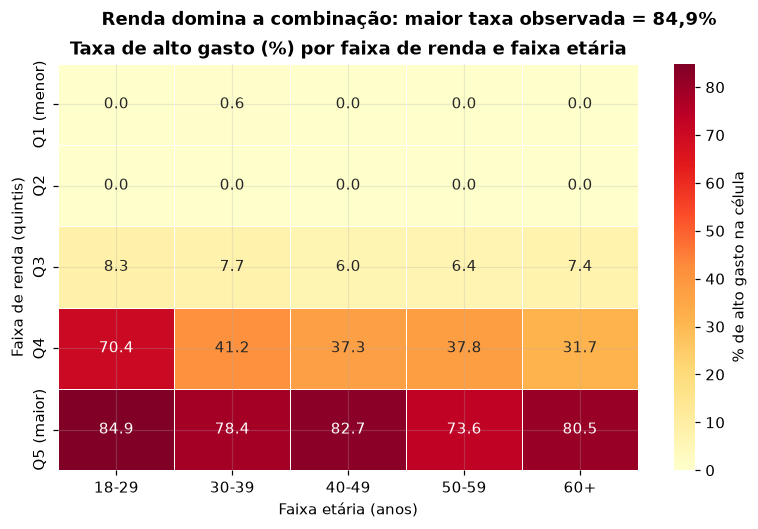

In [37]:
matriz = an.matriz_renda_idade(df)
viz.fig_combinacoes(matriz)
plt.show()


**Renda é o eixo dominante.** Na faixa Q5 (25% de maior renda), 79,5% dos clientes são de alto gasto (IC95%: 75,5–83,0; lift 3,18) e essa faixa concentra 62,9% de todos os clientes de alto gasto. Em Q1 e Q2 a taxa é praticamente zero — a renda funciona como condição quase necessária (não suficiente) para o alto gasto.

**Filhos são o segundo filtro mais forte.** Clientes sem filhos têm taxa de 58,6% (374 de 638), com lift 2,34, e representam 66,8% do grupo de alto gasto. Com um filho a taxa cai para 14,6% e com dois filhos para 3,8%.

**Combinação mais forte (n ≥ 30):** Q5 (maior) | Sem filhos | Ensino superior — 83,4% de alto gasto (272 de 326 clientes), lift 3,32, o que corresponde a 48,9% de todo o grupo de alto gasto. O cruzamento completo renda × filhos mostra o mesmo padrão: a taxa cresce de Q1 para Q5 e cai a cada filho adicional; nenhuma célula de Q1/Q2 atinge 1%.

**Idade não ordena o gasto.** As taxas por faixa etária ficam entre 21,2% e 31,3% — o mapa renda × idade mostra que a variação relevante é horizontal (entre quintis de renda), não vertical (entre faixas etárias). Dentro de Q5, todas as faixas etárias têm taxa alta.

**Cuidado com n pequeno:** "Viúvo(a)" tem taxa de 35,1%, mas são apenas 77 clientes (IC95%: 25,4–46,2%). Já a categoria "Outros" (n = 4) não sustenta nenhuma conclusão. Nenhuma dessas categorias pequenas deve orientar decisões de marketing.


## 12. Análise estatística

Antes de testar, verificamos as premissas: assimetria, normalidade (Shapiro-Wilk) e homogeneidade de variâncias (Levene). Os resultados justificam a escolha de testes **não paramétricos** — o que não é uma formalidade: médias e desvios-padrão seriam resumos ruins para `GastoMensal` (assimetria acima de 9).


In [38]:
premissas = an.verificacao_premissas(df)
premissas


,Variavel,Assimetria_alto,Assimetria_demais,Shapiro_p_alto,Shapiro_p_demais,Levene_p,Normalidade,Variancias
0,Renda,"1,19","0,72","0,00","0,00","0,00",Rejeitada em pelo menos um grupo,Desiguais
1,Idade,"-0,05","0,14","0,00","0,00","0,00",Rejeitada em pelo menos um grupo,Desiguais
2,Gasto total,"0,73","0,92","0,00","0,00","0,11",Rejeitada em pelo menos um grupo,Homogêneas
3,Gasto mensal,"9,27","22,47","0,00","0,00","0,01",Rejeitada em pelo menos um grupo,Desiguais
4,Número de filhos,"1,56","0,29","0,00","0,00","0,01",Rejeitada em pelo menos um grupo,Desiguais
5,Tempo de relacionamento,"-0,25","0,06","0,00","0,00","0,58",Rejeitada em pelo menos um grupo,Homogêneas


A normalidade é rejeitada em todos os grupos para todas as variáveis (p < 0,001), e as variâncias são desiguais para a maioria. Com n grande, o Teorema Central do Limite ampararia a comparação de médias, mas a assimetria forte torna a mediana o resumo mais fiel. Por isso, usamos **Mann-Whitney** para variáveis numéricas e **qui-quadrado** para associações categóricas, sempre com tamanho de efeito e correção de comparações múltiplas (Benjamini-Hochberg, FDR de 5%).


In [39]:
testes = an.testes_estatisticos(df)
testes[["Pergunta", "Teste", "Estatistica", "p_valor", "Tamanho_efeito", "Metrica_efeito", "p_ajustado_BH"]]


,Pergunta,Teste,Estatistica,p_valor,Tamanho_efeito,Metrica_efeito,p_ajustado_BH
0,A renda difere entre alto gasto e demais clien...,Mann-Whitney U,"859.332,50","0,00","0,86",r rank-biserial (grande),"0,00"
1,A idade difere entre os grupos?,Mann-Whitney U,"497.585,50","0,03","0,06",r rank-biserial (desprezível),"0,03"
2,O número de filhos difere entre os grupos?,Mann-Whitney U,"203.527,50","0,00","-0,57",r rank-biserial (grande),"0,00"
3,O tempo de relacionamento difere entre os grupos?,Mann-Whitney U,"548.092,50","0,00","0,17",r rank-biserial (pequeno),"0,00"
4,O gasto mensal normalizado difere entre os gru...,Mann-Whitney U,"841.074,50","0,00","0,79",r rank-biserial (grande),"0,00"
5,O uso de compras com desconto difere entre os ...,Mann-Whitney U,"327.502,50","0,00","-0,30",r rank-biserial (médio),"0,00"
6,A intensidade de visitas ao site difere entre ...,Mann-Whitney U,"224.445,00","0,00","-0,52",r rank-biserial (grande),"0,00"
7,A escolaridade é independente do segmento?,Qui-quadrado (gl=4),"26,52","0,00","0,11",V de Cramér (pequeno),"0,00"
8,O estado civil é independente do segmento?,Qui-quadrado (gl=5),"7,60","0,18","0,06",V de Cramér (desprezível),"0,18"
9,A faixa de renda é independente do segmento?,Qui-quadrado (gl=4),"1.115,50","0,00","0,71",V de Cramér (grande),"0,00"


**Leitura dos testes.** 12 dos 13 testes permanecem significativos após a correção de BH (p ajustado < 0,05). Os efeitos grandes concentram-se em renda (r = 0,86), faixa de renda (V = 0,71), número de filhos (r = -0,57), gasto mensal (r = 0,79) e possuir filhos (V = 0,49).

Três resultados merecem ressalva, porque "significativo" não significa "relevante":

- **Idade**: p ajustado = 0,0332, mas r = 0,06 (desprezível). Com 2.240 clientes, diferenças de 1 ano aparecem como significativas. A conclusão prática é que idade **não** distingue os grupos.
- **Faixa etária**: V de Cramér = 0,09 (desprezível), mesmo com p < 0,01.
- **Estado civil**: p ajustado = 0,1795 — nenhuma evidência de associação com o segmento (V = 0,06).

**Tempo de relacionamento** é significativo com efeito pequeno (r = 0,17), o que é coerente com a interpretação de que tempo não explica o volume de gasto.

**Canal predominante** é significativo com efeito pequeno-médio (V = 0,29), sustentando a leitura de que o catálogo pesa mais no alto gasto.

Nenhum desses resultados estabelece causalidade: são associações observadas em uma base transversal, sem controle de confundidores.


In [40]:
correlacoes = an.correlacoes(df)
correlacoes


,Desfecho,Variavel,N,Spearman_rho,p_valor,Magnitude,p_ajustado_BH
0,Gasto total,Renda anual,2215,"0,85","0,00",grande,"0,00"
1,Gasto total,Idade,2237,"0,16","0,00",pequeno,"0,00"
2,Gasto total,Número de filhos,2240,"-0,48","0,00",médio,"0,00"
3,Gasto total,Tempo de relacionamento,2240,"0,18","0,00",pequeno,"0,00"
4,Gasto total,Total de compras,2240,"0,91","0,00",grande,"0,00"
5,Gasto total,Compras com desconto,2240,"-0,01","0,48",desprezível,"0,48"
6,Gasto total,Visitas ao site por mês,2240,"-0,48","0,00",médio,"0,00"
7,Gasto total,Compras por catálogo,2240,"0,89","0,00",grande,"0,00"
8,Gasto mensal,Renda anual,2213,"0,81","0,00",grande,"0,00"
9,Gasto mensal,Idade,2235,"0,18","0,00",pequeno,"0,00"


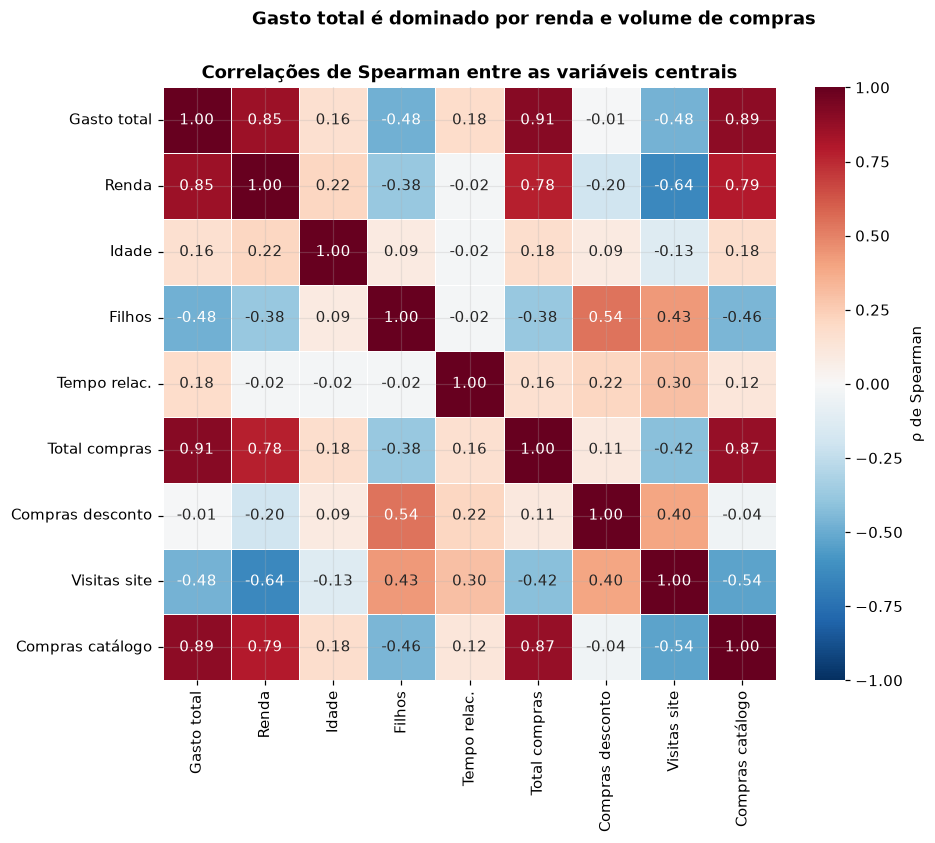

In [41]:
viz.fig_correlacoes(df)
plt.show()


**Correlações (Spearman).** `GastoTotal` tem ρ = 0,852 com renda e ρ = 0,908 com o total de compras: gastar mais é, quase por definição, comprar mais. O achado informativo é a hierarquia dos canais e do comportamento digital: ρ = 0,892 com compras por catálogo, ρ = -0,476 com visitas ao site (negativo: quem mais visita o site compra menos, padrão de navegação sem conversão), ρ = -0,484 com número de filhos e apenas ρ = 0,184 com tempo de relacionamento. Compras com desconto têm ρ = -0,015 (p ajustado = 0,483), ou seja, **nenhuma associação com o gasto acumulado**.


In [42]:
regressao = an.regressao_loglog(df)
regressao


,Modelo,Termo,Coeficiente,IC95_inf,IC95_sup,p_valor,R2,N
0,M1: log(Gasto) ~ log(Renda),log_renda,"2,24","2,15","2,32","0,00","0,57",2212
1,M2: + idade + filhos,log_renda,"2,01","1,93","2,09","0,00","0,64",2212
2,M2: + idade + filhos,Idade,"0,01","0,00","0,01","0,00","0,64",2212
3,M2: + idade + filhos,TotalFilhos,"-0,54","-0,59","-0,49","0,00","0,64",2212


**Regressão log-log (complementar).** Em um modelo log-log, o coeficiente de `log_renda` é a elasticidade: um aumento de 1% na renda associa-se a cerca de 2,24% mais gasto (IC95%: 2,15–2,32), com R² = 0,575. Incluindo idade e filhos, a elasticidade cai para 2,01 e o R² sobe para 0,643; cada filho adicional associa-se a cerca de 54% menos gasto, mantendo a renda constante.

A elasticidade acima de 1 **não** deve ser lida como "renda dobra, gasto quadruplica" no sentido causal: como o gasto tem piso próximo de zero enquanto a renda não, a curva log-log é convexa e superestima a elasticidade em comparações extremas. O modelo serve aqui para quantificar a dominância da renda (R² entre 0,57 e 0,64), não para previsão.


## 13. O tempo de relacionamento altera a interpretação?

O gasto é acumulado desde o cadastro, então clientes mais antigos tiveram mais tempo para gastar. Testamos a robustez da segmentação comparando-a com uma segmentação alternativa pelo **gasto mensal** (mesmo critério de percentil 75) e verificando a concordância entre as duas.


In [43]:
concordancia, sensibilidade = an.sensibilidade_temporal(df)
concordancia


SegmentoMensal,SegmentoGasto,Alto gasto,Demais clientes
0,Alto gasto,353,207
1,Demais clientes,208,1470
2,Acordo observado / Kappa,"81,46","0,51"


In [44]:
sensibilidade


,Grupo,N,Media_tempo_meses,Mediana_tempo_meses,Mediana_gasto_acumulado,Mediana_gasto_mensal
0,Alto gasto,560,"13,05","13,85","1.440,00","108,18"
1,Demais clientes,1678,"11,15","10,96","160,50","19,59"


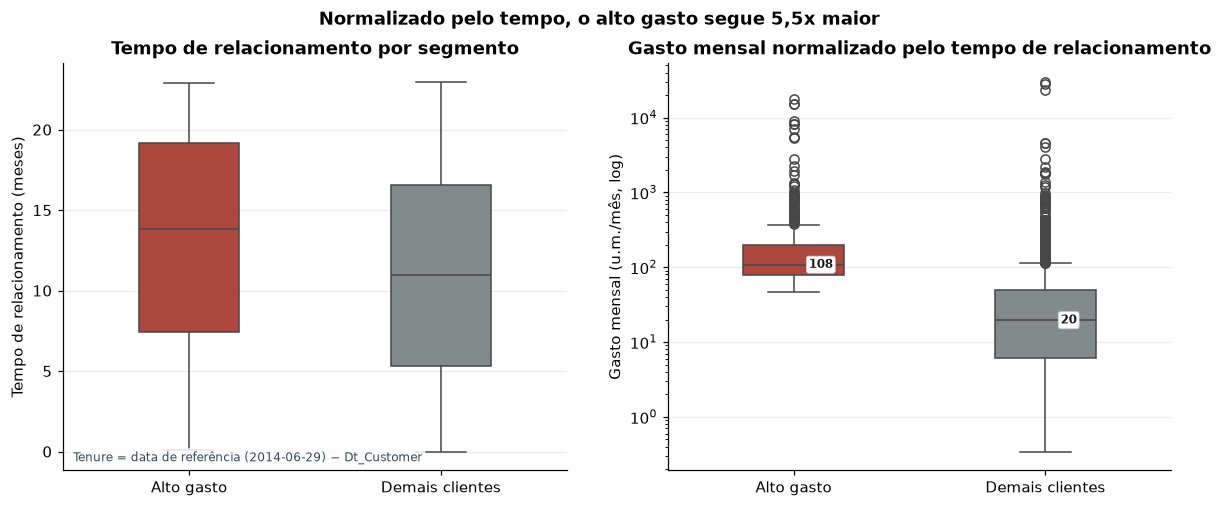

In [45]:
viz.fig_tempo(df, sensibilidade)
plt.show()


**Resultado.** O tempo de relacionamento é ligeiramente maior no alto gasto (13,8 vs 11,0 meses), mas a distância é pequena. Normalizando, a mediana do gasto mensal do alto gasto (108,18 u.m./mês) continua 5,5× a dos demais (19,59 u.m./mês).

A segmentação pelo gasto mensal concorda com a segmentação pelo gasto acumulado em 81,5% dos casos (kappa de Cohen = 0,51, concordância moderada): dos 560 clientes de alto gasto acumulado, 353 permanecem no quartil superior quando se usa o gasto mensal. A conclusão é que **o tempo de relacionamento não inverte a leitura**: ele explica parte da variabilidade (ρ = 0,184), mas não é o mecanismo por trás da concentração de gasto. Mantivemos a segmentação principal pelo gasto acumulado, como definido no escopo, e usamos o gasto mensal apenas como verificação.

**Limitação:** a proxy de data de referência (29-06-2014) subestima o tempo de relacionamento e, portanto, superestima o gasto mensal — mas esse viés atinge os dois grupos de forma semelhante, preservando a comparação.


## 14. Conclusões

**Respostas às perguntas de pesquisa**

1. **Perfil do cliente que mais gasta.** Renda alta (mediana de 75.296 u.m., 1,8× os demais), sem filhos, escolaridade superior (destaque para doutorado), idade próxima à mediana da base — não é um perfil etário, é um perfil de capacidade de consumo.
2. **Canal preferido.** Loja física em volume (8,5 compras por cliente); o catálogo é o canal que mais diferencia o grupo (5,9 vs 1,6).
3. **Descontos.** Usam menos ofertas que os demais (1,86 vs 2,48 compras com desconto), embora quase todos já tenham usado alguma.
4. **Categorias.** Vinhos (49,6% da cesta) e carnes (30,6%) concentram o gasto do grupo.
5. **Público-alvo.** Faixa Q5 de renda responde por 62,9% dos clientes de alto gasto; clientes sem filhos, por 66,8%.
6. **Características do público.** Renda mediana 75.296 u.m., 0,38 filhos em média, 45 anos de mediana, predominância de graduação/doutorado.
7. **Participação no gasto total.** Os 25% de maior gasto respondem por **61,51%** do gasto; os 10% maiores, por 30,2%.
8. **Renda e gasto.** Associação forte e positiva (ρ = 0,852; R² = 0,64 no modelo log-log com controles), sem pretensão causal.
9. **Tempo de relacionamento.** Influencia pouco (ρ = 0,184); a conclusão se mantém com o gasto mensal (81,5% de concordância entre segmentações).

**Recomendações de marketing (derivadas dos dados, não testadas em campo)**

- Priorizar o cruzamento **alta renda + sem filhos + ensino superior**: 83,4% desse perfil está no quartil superior e ele concentra 48,9% do grupo de alto gasto.
- Tratar o **catálogo** como canal de relacionamento do segmento premium: é onde o grupo mais se distancia do restante.
- Priorizar **vinhos e carnes** em sortimento e comunicação para esse público; não usar desconto como principal alavanca, já que o segmento usa menos ofertas.
- Não segmentar por idade nem por estado civil: os dados não sustentam associação relevante.


## 15. Limitações

1. **Gasto como proxy de faturamento.** A base não tem lucro, margem nem valor monetário por transação. `GastoTotal` é a melhor aproximação disponível do valor gerado pelo cliente, e não receita líquida.
2. **Estudo descritivo e transversal.** Todas as relações são associações observadas em um retrato único; nenhuma conclusão causal é possível. "Clientes sem filhos gastam mais" não implica que ter filhos reduza o gasto.
3. **`NumDealsPurchases` não comprova cupom.** O atributo registra compras com ofertas/descontos, sem identificar o mecanismo promocional.
4. **Gasto acumulado depende do tempo de relacionamento.** Tratado com a normalização mensal e a análise de concordância da Seção 13, mas não eliminado.
5. **Data de referência é uma proxy (29-06-2014).** O nível do gasto mensal é sensível a essa escolha; a comparação entre grupos não é.
6. **Amostra da base, não da população.** Os resultados descrevem os 2.240 clientes presentes; não representam necessariamente todos os consumidores da empresa, e não há informação sobre clientes que deixaram a base.
7. **Ausências não imputadas.** 25 clientes sem renda utilizável ficam fora das análises de renda e de algumas combinações de perfil — 1,1% da base, sem impacto material nas conclusões, mas com efeito no n exato de cada tabela.
8. **Não há dados de margem nem de custo promocional**, o que impede avaliar rentabilidade dos segmentos ou o retorno de descontos.
9. **Categorização em faixas** (quintis de renda, décadas de idade) é uma escolha analítica; outras divisões mudariam a forma das tabelas de público-alvo, mas não a direção dos resultados (renda alta e ausência de filhos concentram o alto gasto).


## 16. Referências

- KAGGLE. *Customer Personality Analysis* (dataset `marketing_campaign.csv`, 2.240 registros, 29 atributos). Disponível em: https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis. Acesso em: 2026.
- MCKINNEY, W. *Python for Data Analysis*. 3. ed. O'Reilly Media, 2022.
- VIRTANEN, P. et al. SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, v. 17, p. 261–272, 2020.
- WASKOM, M. seaborn: statistical data visualization. *Journal of Open Source Software*, v. 6, n. 60, p. 3021, 2021.
- SEABOLD, S.; PERKTOLD, J. statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*, 2010.
- BENJAMINI, Y.; HOCHBERG, Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society B*, v. 57, n. 1, p. 289–300, 1995.
- WILSON, E. B. Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association*, v. 22, n. 158, p. 209–212, 1927.
- COHEN, J. *Statistical Power Analysis for the Behavioral Sciences*. 2. ed. Lawrence Erlbaum, 1988.
